# Cleaning up noisy quantum results with a built-in "noise meter"

**The short version.** Today's quantum computers make mistakes. One popular fix is to run the same program at 1×, 3× and 5× the noise on purpose, then draw a line back to "zero noise" and read off the answer. That works only if the machine's noise stays the same between runs. Real machines drift.

**Our idea (SA-ZNE).** Our test program obeys a simple counting rule: the number of 1s in every correct answer is fixed. So we can count how often the machine breaks that rule. That count acts as a noise meter, read from the same results and needing no extra runs. We then draw the line against the *measured* noise instead of the *assumed* 1×, 3×, 5×.

This notebook is a small, self-contained version of the full experiment. It runs on a simulated IBM 5-qubit chip with realistic noise and takes about 1–2 minutes. No real quantum hardware or account is needed.

**Step 1: install the tools.** This installs Qiskit (IBM's quantum programming kit), its simulator, and a few plotting and math libraries. On Google Colab this takes under a minute.

In [1]:
!pip install -q qiskit qiskit-aer qiskit-ibm-runtime matplotlib numpy scipy

**Step 2: load the tools.** We also fix the random seeds so that anyone who reruns this gets exactly the same numbers.

In [2]:
import time, copy
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

SEED = 2026
rng = np.random.default_rng(SEED)
T0 = time.time()
N = 4                      # number of qubits
print("ready")

ready


**Step 3: the test problem.** We simulate a chain of 4 tiny magnets ("spins") that start in an up-down-up-down pattern and interact over a short time. We make 20 random versions of the chain, each run for 1, 2 or 3 time steps (60 test problems).

The key property: the program never changes how many magnets point up. A perfect machine always returns answers with exactly two 1s. We also compute the exact correct answer on a normal computer, so we can score every method.

In [3]:
def chain_circuit(J, D, h, steps, dt=0.25):
    qc = QuantumCircuit(N)
    for q in range(1, N, 2):
        qc.x(q)                                   # start as up-down-up-down
    for _ in range(steps):
        for parity in (0, 1):
            for i in range(parity, N - 1, 2):     # neighbours interact
                qc.rxx(2*J[i]*dt, i, i+1); qc.ryy(2*J[i]*dt, i, i+1); qc.rzz(2*J[i]*D[i]*dt, i, i+1)
        for i in range(N):
            qc.rz(2*h[i]*dt, i)                   # local magnetic field
    return qc

idx = np.arange(2**N)
Z = np.array([1 - 2*((idx >> i) & 1) for i in range(N)])
observable = sum(((-1)**i) * Z[i] for i in range(N)) / N    # "how much of the up-down pattern survives"
rule_ok = ((1 - Z)//2).sum(0) == N//2                      # answers with exactly two 1s
P_RANDOM = rule_ok.mean()                                  # chance a pure-noise answer passes the rule

problems = []
for k in range(20):
    J, D, h = rng.uniform(.5, 1.5, N-1), rng.uniform(.3, 1.5, N-1), rng.uniform(-1, 1, N)
    for steps in (1, 2, 3):
        qc = chain_circuit(J, D, h, steps)
        ideal = float((np.abs(Statevector(qc).data)**2) @ observable)
        problems.append((qc, ideal))
print(len(problems), "test problems; example exact answers:", [round(p[1], 3) for p in problems[:4]])

60 test problems; example exact answers: [0.477, -0.095, 0.24, 0.151]


**Step 4: a realistic but imperfect fake quantum computer.** `FakeManilaV2` copies the error rates of a real 5-qubit IBM chip. To mimic drift, we can turn its noise down or up (×0.7 to ×1.3) between runs, the way a real chip's quality changes between calibrations.

In [4]:
BASE = FakeManilaV2()
GAINS = [0.7, 0.85, 1.0, 1.15, 1.3]

def drifted(backend, g):
    if g == 1.0:
        return backend
    b = copy.deepcopy(backend); T = b.target
    for op in T.operation_names:
        if op == "measure":
            continue
        for _, pr in T[op].items():
            if pr is not None and pr.error is not None:
                pr.error = min(pr.error * g, 0.75)
    for qp in T.qubit_properties:
        if qp is not None and qp.t1:
            qp.t1 /= g; qp.t2 = qp.t2 / g if qp.t2 else qp.t2
    return b

nm = NoiseModel.from_backend(BASE)
LAYOUT = [0, 1, 2, 3]
READOUT = [np.array(nm._local_readout_errors[(q,)].probabilities) for q in LAYOUT]   # chance of misreading each qubit
print("readout error per qubit:", [round(float(m[0,1] + m[1,0])/2, 3) for m in READOUT])

readout error per qubit: [0.035, 0.022, 0.096, 0.014]


**Step 5: turn up the noise on purpose.** "Folding" runs the program, then its exact reverse, then the program again. Mathematically nothing changes, but the hardware makes about 3× as many mistakes. Doing it twice gives about 5×. We run every problem at 1×, 3× and 5× on every drift setting. This is the slowest step, around a minute.

In [5]:
def fold(u, lam):
    qc = u.copy()
    for _ in range((lam - 1)//2):
        qc.barrier(); qc.compose(u.inverse(), inplace=True); qc.barrier(); qc.compose(u, inplace=True)
    return qc

LAMS = [1, 3, 5]
isa = []
for qc, ideal in problems:
    t = transpile(qc, BASE, optimization_level=1, initial_layout=LAYOUT, seed_transpiler=7)
    isa.append(t)

clean_probs = {}    # (gain, problem, lam) -> probabilities before readout errors
for g in GAINS:
    b = drifted(BASE, g); sim = AerSimulator.from_backend(b, method="density_matrix")
    circs = []
    for t in isa:
        for lam in LAMS:
            c = transpile(fold(t, lam), b, optimization_level=0, layout_method="trivial", routing_method="none", scheduling_method="alap")
            c.save_density_matrix(qubits=LAYOUT, label="rho"); circs.append(c)
    res = sim.run(circs, shots=1).result()
    for k in range(len(circs)):
        clean_probs[(g, k // 3, LAMS[k % 3])] = np.clip(np.real(np.diag(np.asarray(res.data(k)["rho"]))), 0, None)
print(f"simulated {len(clean_probs)} noisy circuits in {time.time()-T0:.0f}s")

simulated 900 noisy circuits in 35s


**Step 6: the methods we compare.** For each run we take 4,000 samples, like a real experiment, and correct for qubits being misread, using a quick calibration. Then:

* **Raw**: just average the results.
* **Rule filter (PS)**: throw away answers that break the "exactly two 1s" rule.
* **Standard ZNE (PS+ZNE-lin)**: filter, then draw a line through the 1×, 3×, 5× results back to zero noise. This *assumes* the noise really was 1×, 3×, 5×.
* **Our SA-ZNE**: filter, then draw the line against the *measured* noise from the rule-breaking rate. The measured noise level is x = −ln f, where f is how far the pass rate sits above the pure-noise pass rate.

In [6]:
def apply_matrices(p, mats):
    t = p.reshape([2]*N)
    for i, m in enumerate(mats):
        ax = N - 1 - i
        t = np.moveaxis(np.tensordot(t, m, axes=([ax], [0])), -1, ax)
    return t.reshape(-1)

def estimate(counts_list, cal):
    s, P = [], []
    for c in counts_list:
        q = apply_matrices(c, [np.linalg.inv(m) for m in cal])      # undo misreads
        P.append(q[rule_ok].sum() / q.sum()); s.append(q[rule_ok] @ observable[rule_ok] / q[rule_ok].sum())
        if len(s) == 1:
            raw = q @ observable / q.sum()
    s, P = np.array(s), np.array(P)
    f = np.clip((P - P_RANDOM) / (1 - P_RANDOM), 1e-3, 1)
    return {"Raw": raw, "Rule filter (PS)": s[0],
            "Standard ZNE (PS+ZNE-lin)": np.polyval(np.polyfit(LAMS, s, 1), 0),
            "Our SA-ZNE": np.polyval(np.polyfit(-np.log(f), s, 1), 0)}
print("methods defined")

methods defined


**Step 7: a fair test.** We repeat each problem 20 times with fresh random sampling, under two conditions:

* **Steady machine**: all three noise levels are run on the nominal chip.
* **Drifting machine**: each of the three runs lands on a randomly drifted chip (×0.7 to ×1.3).

We score each method by its average distance from the exact answer (lower is better), and compare methods on the very same samples.

In [7]:
METHODS = ["Raw", "Rule filter (PS)", "Standard ZNE (PS+ZNE-lin)", "Our SA-ZNE"]
err = {c: {m: [] for m in METHODS} for c in ("steady", "drifting")}
for c in err:
    for k, (_, ideal) in enumerate(problems):
        per = {m: [] for m in METHODS}
        for rep in range(20):
            r = np.random.default_rng([SEED, k, rep, len(c)])
            gs = [1.0]*3 if c == "steady" else list(r.choice(GAINS, 3))
            cal = []
            for m in READOUT:
                e01, e10 = r.binomial(4000, m[0,1])/4000, r.binomial(4000, m[1,0])/4000
                cal.append(np.array([[1-e01, e01], [e10, 1-e10]]))
            counts = [r.multinomial(4000, apply_matrices(clean_probs[(g, k, lam)], READOUT))/4000 for g, lam in zip(gs, LAMS)]
            for m, v in estimate(counts, cal).items():
                per[m].append(abs(v - ideal))
        for m in METHODS:
            err[c][m].append(np.mean(per[m]))

def boot_ci(x, B=4000):
    x = np.asarray(x); mm = np.random.default_rng(0).choice(x, (B, len(x))).mean(1)
    return np.percentile(mm, [2.5, 97.5])

print(f"{'method':28s} {'steady':>18s} {'drifting':>18s}")
for m in METHODS:
    print(f"{m:28s} " + "  ".join(f"{np.mean(err[c][m]):.4f} ({boot_ci(err[c][m])[0]:.4f}-{boot_ci(err[c][m])[1]:.4f})" for c in err))
for c in err:
    d = np.array(err[c]["Our SA-ZNE"]) - np.array(err[c]["Standard ZNE (PS+ZNE-lin)"])
    lo, hi = boot_ci(d)
    print(f"{c}: SA-ZNE minus standard ZNE = {d.mean():+.4f}  (95% range {lo:+.4f} to {hi:+.4f}; {d.mean()/np.mean(err[c]['Standard ZNE (PS+ZNE-lin)']):+.0%})")
pen = {m: np.mean(err['drifting'][m]) - np.mean(err['steady'][m]) for m in METHODS[2:]}
print("accuracy lost to drift:", {k: round(float(v), 4) for k, v in pen.items()})
print(f"total runtime {time.time()-T0:.0f}s")

method                                   steady           drifting
Raw                          0.0724 (0.0597-0.0858)  0.0725 (0.0596-0.0859)
Rule filter (PS)             0.0446 (0.0365-0.0533)  0.0447 (0.0363-0.0537)
Standard ZNE (PS+ZNE-lin)    0.0282 (0.0235-0.0336)  0.0305 (0.0258-0.0359)
Our SA-ZNE                   0.0335 (0.0275-0.0404)  0.0344 (0.0284-0.0413)
steady: SA-ZNE minus standard ZNE = +0.0053  (95% range +0.0036 to +0.0073; +19%)
drifting: SA-ZNE minus standard ZNE = +0.0039  (95% range +0.0019 to +0.0060; +13%)
accuracy lost to drift: {'Standard ZNE (PS+ZNE-lin)': 0.0023, 'Our SA-ZNE': 0.0009}
total runtime 37s


**Step 8: the picture.** Shorter bars mean answers closer to the truth. Compare the two right-hand bars in each group.

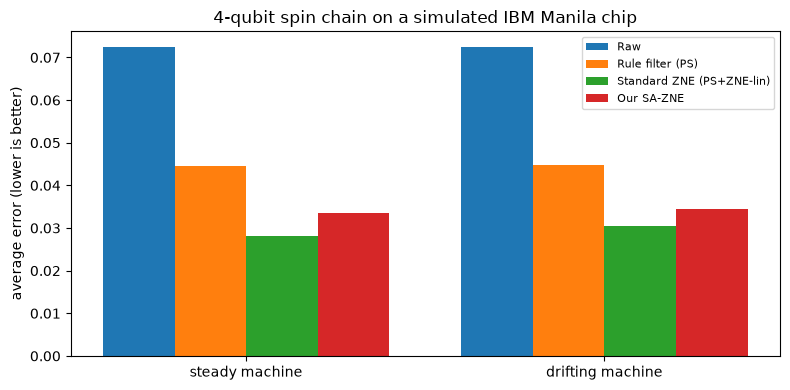

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
w = 0.2
for j, m in enumerate(METHODS):
    vals = [np.mean(err[c][m]) for c in err]
    ax.bar(np.arange(2) + (j - 1.5)*w, vals, w, label=m)
ax.set_xticks([0, 1]); ax.set_xticklabels(["steady machine", "drifting machine"])
ax.set_ylabel("average error (lower is better)"); ax.legend(fontsize=8); ax.set_title("4-qubit spin chain on a simulated IBM Manila chip")
plt.tight_layout(); plt.show()

**Step 9: the verdict, computed from the numbers above.** No hand-written conclusion: the code reads the results and states them.

In [9]:
d_st = np.mean(err["steady"]["Our SA-ZNE"]) - np.mean(err["steady"]["Standard ZNE (PS+ZNE-lin)"])
d_dr = np.array(err["drifting"]["Our SA-ZNE"]) - np.array(err["drifting"]["Standard ZNE (PS+ZNE-lin)"])
lo, hi = boot_ci(d_dr)
if hi < 0:
    print("On the drifting machine, SA-ZNE is clearly more accurate than standard ZNE.")
elif lo > 0:
    print("On the drifting machine, SA-ZNE is clearly LESS accurate than standard ZNE in this small demo.")
else:
    print("On the drifting machine, the two methods cannot be told apart in this small demo.")
print(f"Accuracy lost to drift: standard ZNE {pen['Standard ZNE (PS+ZNE-lin)']:.4f}, SA-ZNE {pen['Our SA-ZNE']:.4f}",
      "-> SA-ZNE is more robust to drift" if pen['Our SA-ZNE'] < pen['Standard ZNE (PS+ZNE-lin)'] else "-> no robustness gain")

On the drifting machine, SA-ZNE is clearly LESS accurate than standard ZNE in this small demo.
Accuracy lost to drift: standard ZNE 0.0023, SA-ZNE 0.0009 -> SA-ZNE is more robust to drift


**How to read this, honestly.**

* Filtering by the rule plus extrapolation removes most of the error that comes from noise.
* When the machine drifts between runs, standard ZNE loses accuracy because its "1×, 3×, 5×" assumption becomes wrong. The noise meter reads drift from the same results, so SA-ZNE should lose less, and that is what the "accuracy lost to drift" line checks.
* Being *robust* is not the same as being *more accurate*. On this small 4-qubit chip, where one qubit has a 10% chance of being misread, the noise meter is itself noisy and a little biased. So SA-ZNE can still end up behind overall. The verdict above reports whichever happened.
* The full study used 6-qubit chains on simulated 127- and 133-qubit IBM chips (Sherbrooke and Torino), two folding styles and a held-out confirmation run. Its numbers are in the project README.
* This is not a brand-new family of methods. It combines known ideas: ZNE with a measured noise axis (IC-ZNE, arXiv:2403.01608), symmetry filtering (Bonet-Monroig et al., arXiv:1807.10050) and symmetry-learned extrapolation (GUESS). What is new is reading the noise level from the same filtered results, with no extra circuits, to correct for drift.
* All results are from simulation. Nothing was run on real quantum hardware.